# Learning predictions for downstream decisions

This native Julia companion preserves the public formulas, finite vertex order, inputs and original seeds. Julia computes the oracle decisions, losses and gradients; Zygote supplies the native counterpart of the Python tensor adapter. Vertex indices in displayed tables retain the original zero-based convention. Julia ArgumentError corresponds to Python ValueError for invalid inputs. Figures use the requested dark theme and outputs are saved under `outputs/julia`.

## Separating prediction error from decision regret

Let the feasible decisions be the rows of a supplied matrix $V$. For a cost vector $c$, an exact finite oracle returns

$$
w^{*}(c)=\arg\min_{w\in V} c^{\mathsf T}w.
$$

Here, $V$ is the finite list of feasible vertices, $c$ contains the costs, and $w^{*}(c)$ is the first listed decision with the smallest linear cost. The implemented oracle is exact for the convex hull of these supplied vertices because a linear objective reaches its minimum at a vertex. It does not create a feasible region or enumerate missing vertices.

### Regret from a Predicted Cost

If $\widehat c$ is a predicted cost vector, the decision loss is

$$
L_{\mathrm{SPO}}(\widehat c,c)
=
c^{\mathsf T}w^{*}(\widehat c)
-
c^{\mathsf T}w^{*}(c).
$$

The vector $c$ is the observed cost, $\widehat c$ is its prediction, and the two oracle calls select the predicted and observed best decisions. The loss is the extra observed cost caused by acting on the prediction. It answers a different question from a squared prediction error.

Row,Symbol,Description
,String,String
1,V,Matrix whose rows are the supplied feasible vertices
2,c,Observed linear cost vector
3,c hat,Predicted linear cost vector
4,w*(c),First supplied vertex with the lowest observed cost
5,L_SPO,Extra observed cost caused by the predicted decision
6,L_SPO+,Convex upper surrogate returned by RiskLabAI


Row,Vertex,Decision component 1,Decision component 2
,Int64,Float64,Float64
1,0,0.0,0.0
2,1,1.0,0.0
3,2,0.0,1.0
4,3,0.2,0.8


Row,Vertex,Observed objective,Predicted objective,Transformed objective,Observed oracle,Predicted oracle,Transformed oracle
,Int64,Float64,Float64,Float64,String,String,String
1,0,0.0,0.0,0.0,Fail,Fail,Fail
2,1,2.0,-0.4,-2.8,Fail,Pass,Pass
3,2,-1.0,0.8,2.6,Pass,Fail,Fail
4,3,-0.4,0.56,1.52,Fail,Fail,Fail


Row,Quantity,Value,Check
,String,Float64,String
1,Observed best vertex,2.0,Pass
2,Predicted selected vertex,1.0,Pass
3,Decision regret,3.0,Pass
4,Manual SPO+ loss,5.4,Pass
5,RiskLabAI SPO+ loss,5.4,Pass


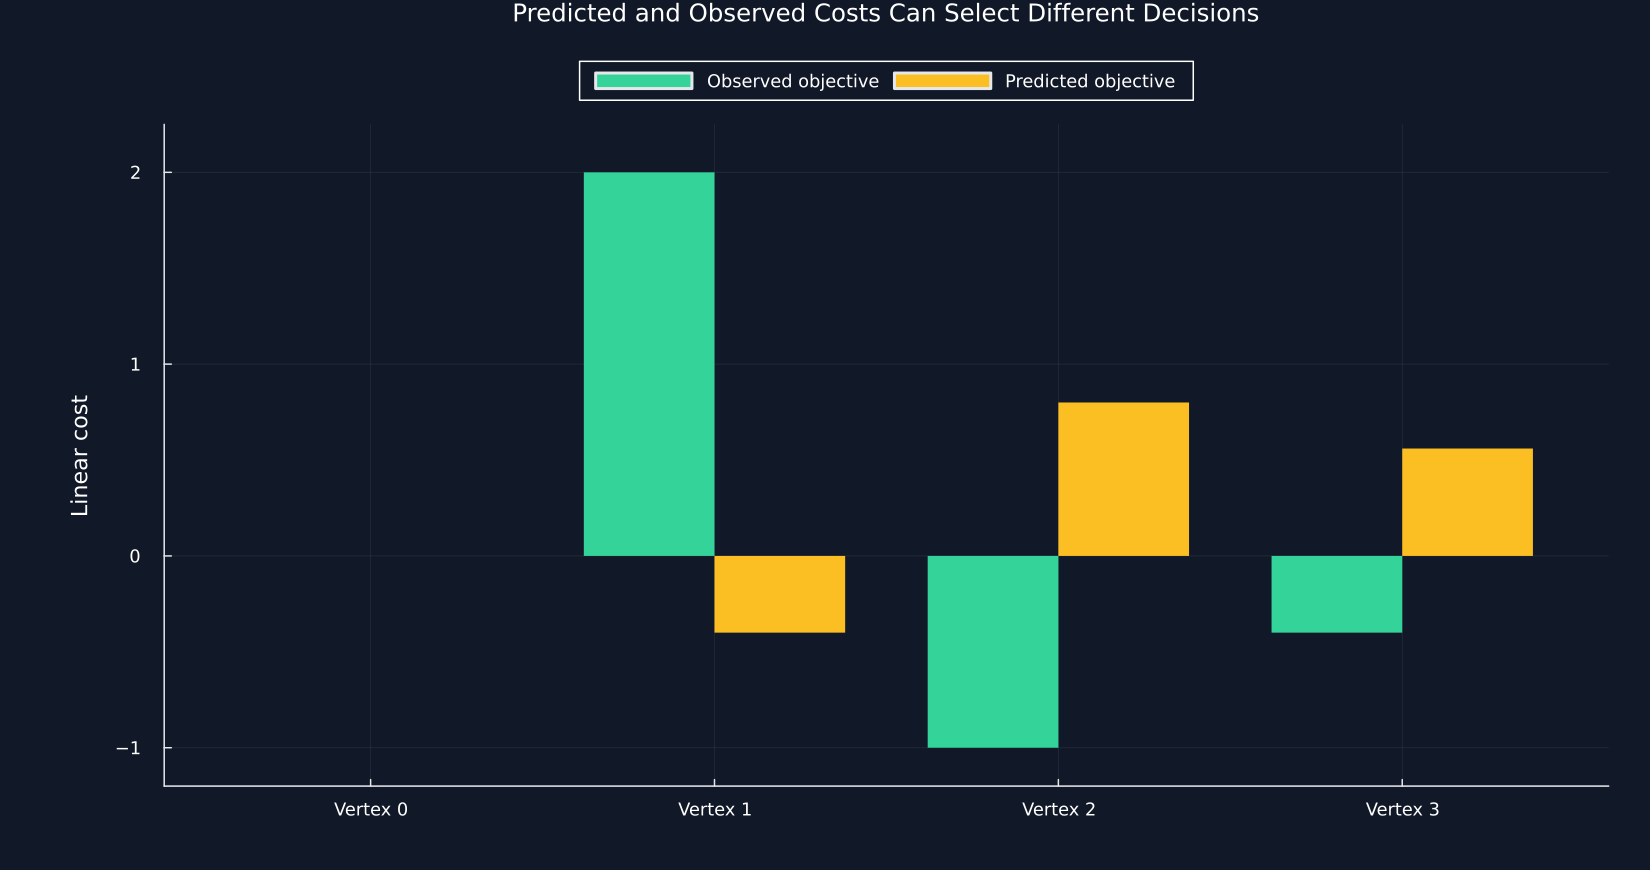

Row,Prediction,Mean squared error,Selected vertex,Decision regret
,String,Float64,Int64,Float64
1,"Lower error, wrong decision",2.4e-5,1,0.01
2,"Higher error, right decision",0.0860333,0,0.0


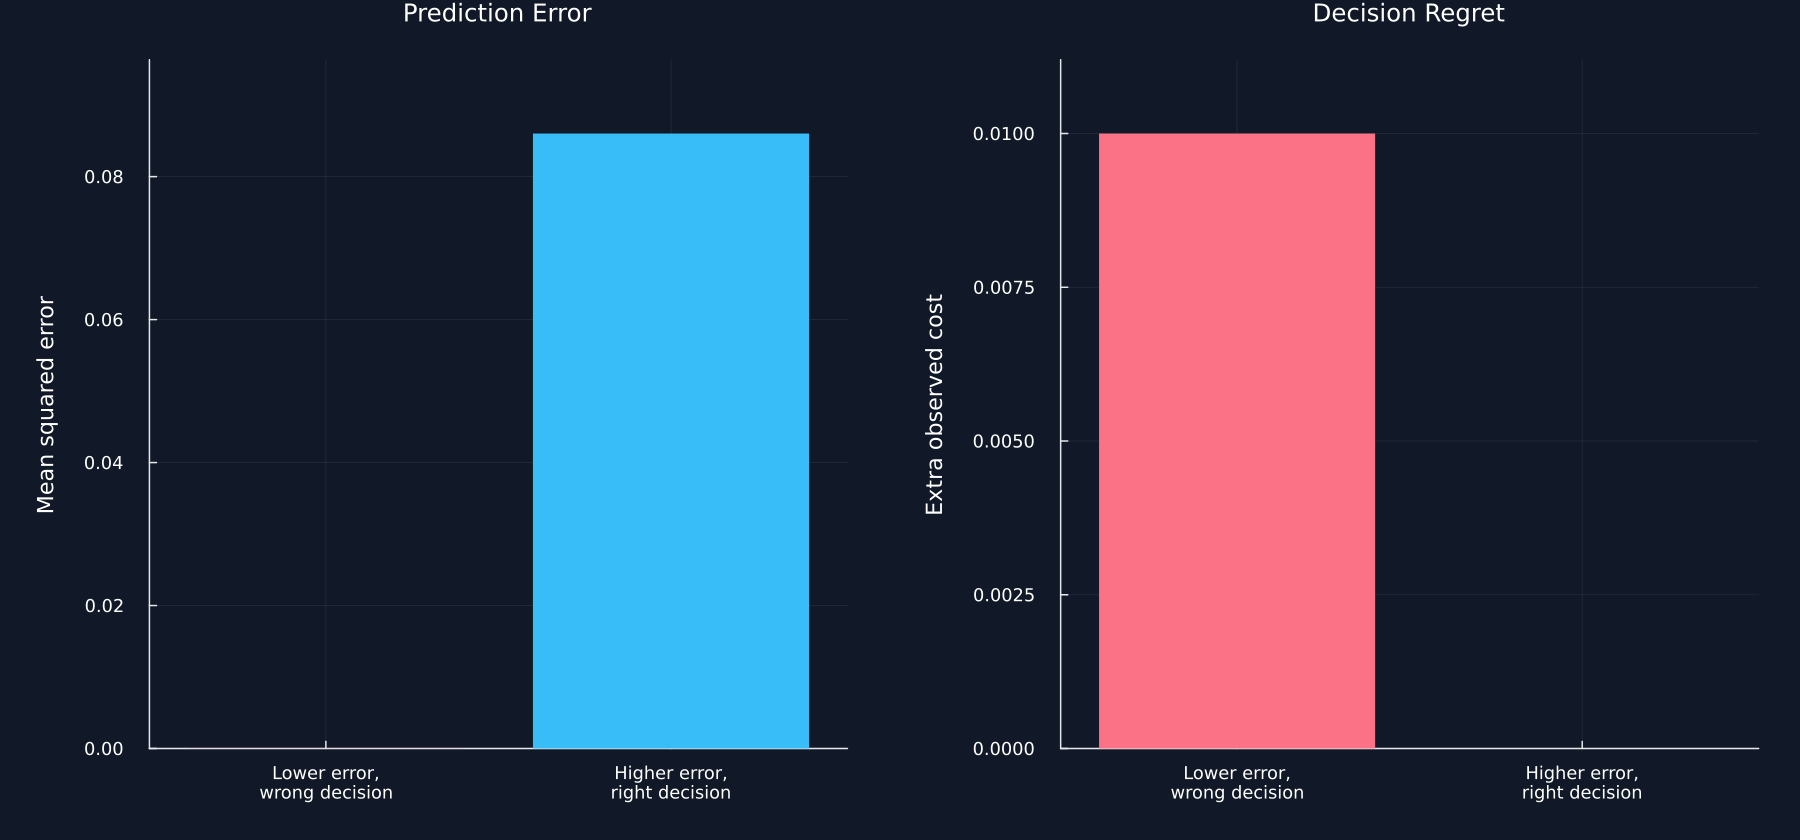

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("27_decision_focused_learning");
using CSV, TOML, Printf, Zygote, Combinatorics
using RiskLabAI.Optimization: spo_plus_loss,spo_plus,robust_mean_variance
default(left_margin=10Plots.mm,bottom_margin=8Plots.mm)
violet = "#C084FC"
function table(frame,name,caption)
    shown = copy(frame)
    for column in names(shown)
        if eltype(shown[!,column])<:Bool
            shown[!,column] = ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter28-"*replace(name,"_"=>"-"))
    return nothing
end
random_root = joinpath("..","data","chapter27_random_inputs")
random_manifest = TOML.parsefile(joinpath(random_root,"inputs.toml"))["files"]
function primitive(name)
    path = joinpath(random_root,name)
    return Matrix{Float64}(CSV.read(path,DataFrame))
end
vertices = []
true_cost,predicted_cost = [2.0,-1.0],[-0.4,0.8]
result = spo_plus_loss(predicted_cost,true_cost,vertices)
notation = DataFrame("Symbol"=>["V","c","c hat","w*(c)","L_SPO","L_SPO+"],"Description"=>["Matrix whose rows are the supplied feasible vertices","Observed linear cost vector","Predicted linear cost vector","First supplied vertex with the lowest observed cost","Extra observed cost caused by the predicted decision","Convex upper surrogate returned by RiskLabAI"])
table(notation,"decision_loss_notation","Notation for decision loss and the SPO+ surrogate.")
vertex_table = DataFrame("Vertex"=>0:3,"Decision component 1"=>vertices[:,1],"Decision component 2"=>vertices[:,2])
table(vertex_table,"finite_feasible_vertices","Explicitly supplied feasible vertices in the exact example.")
true_objectives = vertices*true_cost
predicted_objectives = vertices*predicted_cost
transformed_objectives = vertices*(2predicted_cost-true_cost)
oracle_table = DataFrame("Vertex"=>0:3,"Observed objective"=>true_objectives,"Predicted objective"=>predicted_objectives,"Transformed objective"=>transformed_objectives,"Observed oracle"=>(1:4).==argmin(true_objectives),"Predicted oracle"=>(1:4).==argmin(predicted_objectives),"Transformed oracle"=>(1:4).==argmin(transformed_objectives))
table(oracle_table,"finite_oracle_checks","Exhaustive objective values and selected vertices.")
decision_regret = dot(true_cost,vertices[argmin(predicted_objectives),:])-minimum(true_objectives)
manual_loss = dot(true_cost-2predicted_cost,vertices[argmin(transformed_objectives),:])+dot(2predicted_cost-true_cost,vertices[argmin(true_objectives),:])
loss_checks = DataFrame("Quantity"=>["Observed best vertex","Predicted selected vertex","Decision regret","Manual SPO+ loss","RiskLabAI SPO+ loss"],"Value"=>[argmin(true_objectives)-1,argmin(predicted_objectives)-1,decision_regret,manual_loss,result.loss],"Check"=>[true,true,decision_regret>=0,manual_loss≈result.loss,result.loss>=decision_regret-1e-12])
table(loss_checks,"spo_loss_components","Decision regret and exhaustive SPO+ checks.")
@assert all(loss_checks.Check)
plot_data = DataFrame("Decision"=>["Vertex "*string(i) for i in 0:3],"Observed cost"=>true_objectives,"Predicted cost"=>predicted_objectives)
save_data(plot_data,paths,"exact_cost_decisions")
p1 = bar((0:3).-0.19,true_objectives;bar_width=0.38,color=palette.green,label="Observed objective",linealpha=0,xticks=(0:3,plot_data.Decision),ylabel="Linear cost",title="Predicted and Observed Costs Can Select Different Decisions",legend=:outertop,legend_columns=2,size=(1100,580),ylims=(-1.2,2.25),left_margin=15Plots.mm)
bar!(p1,(0:3).+0.19,predicted_objectives;bar_width=0.38,color=palette.amber,label="Predicted objective",linealpha=0)
save_figure(p1,paths,"exact_cost_decisions")
counter_true = [0.0,0.01,10.0]
predictions = ["Lower error, wrong decision"=>[0.006,0.004,10.0],"Higher error, right decision"=>[0.0,0.1,9.5]]
counter_table = DataFrame([(Prediction=name,mse=mean(abs2,prediction-counter_true),selected=argmin(prediction)-1,regret=counter_true[argmin(prediction)]-minimum(counter_true)) for (name,prediction) in predictions])
rename!(counter_table,["Prediction","Mean squared error","Selected vertex","Decision regret"])
@assert counter_table[1,"Mean squared error"]<counter_table[2,"Mean squared error"]
@assert counter_table[1,"Decision regret"]>counter_table[2,"Decision regret"]
table(counter_table,"prediction_error_decision_error","A lower prediction error need not produce a lower decision regret.")
save_data(counter_table,paths,"mse_regret_contrast")
ticklabels = ["Lower error,
wrong decision","Higher error,
right decision"]
panels = [bar(1:2,counter_table[!,column];color=[palette.rose,palette.cyan],linealpha=0,xticks=(1:2,ticklabels),ylabel,title,legend=false,ylims=(0,1.12maximum(counter_table[!,column]))) for (column,title,ylabel) in [("Mean squared error","Prediction Error","Mean squared error"),("Decision regret","Decision Regret","Extra observed cost")]]
save_figure(plot(panels...;layout=(1,2),size=(1200,560)),paths,"mse_regret_contrast")


## The SPO+ Surrogate

The finite SPO+ loss used here is

$$
L_{\mathrm{SPO+}}(\widehat c,c)
=
(c-2\widehat c)^{\mathsf T}w^{*}(2\widehat c-c)
+
(2\widehat c-c)^{\mathsf T}w^{*}(c).
$$

The transformed oracle uses the cost $2\widehat c-c$. Under the stated linear decision setting, this loss is a convex upper surrogate for decision loss. One selected subgradient with respect to $\widehat c$ is

$$
g(\widehat c,c)
=
2\left[w^{*}(c)-w^{*}(2\widehat c-c)\right].
$$

The vector $g(\widehat c,c)$ gives a valid supporting slope at the supplied prediction. At ties, the released implementation selects the first supplied vertex, so the returned subgradient is deterministic but need not be unique.

Row,Component,RiskLabAI subgradient,Zygote gradient,Absolute difference
,Int64,Float64,Float64,Float64
1,1,-2.0,-2.0,0.0
2,2,2.0,2.0,0.0


Row,Check,Value,Pass
,String,Float64,String
1,Random comparison points,100.0,Pass
2,Smallest convexity margin,-1.77636e-15,Pass
3,Largest convexity margin,2.81512,Pass


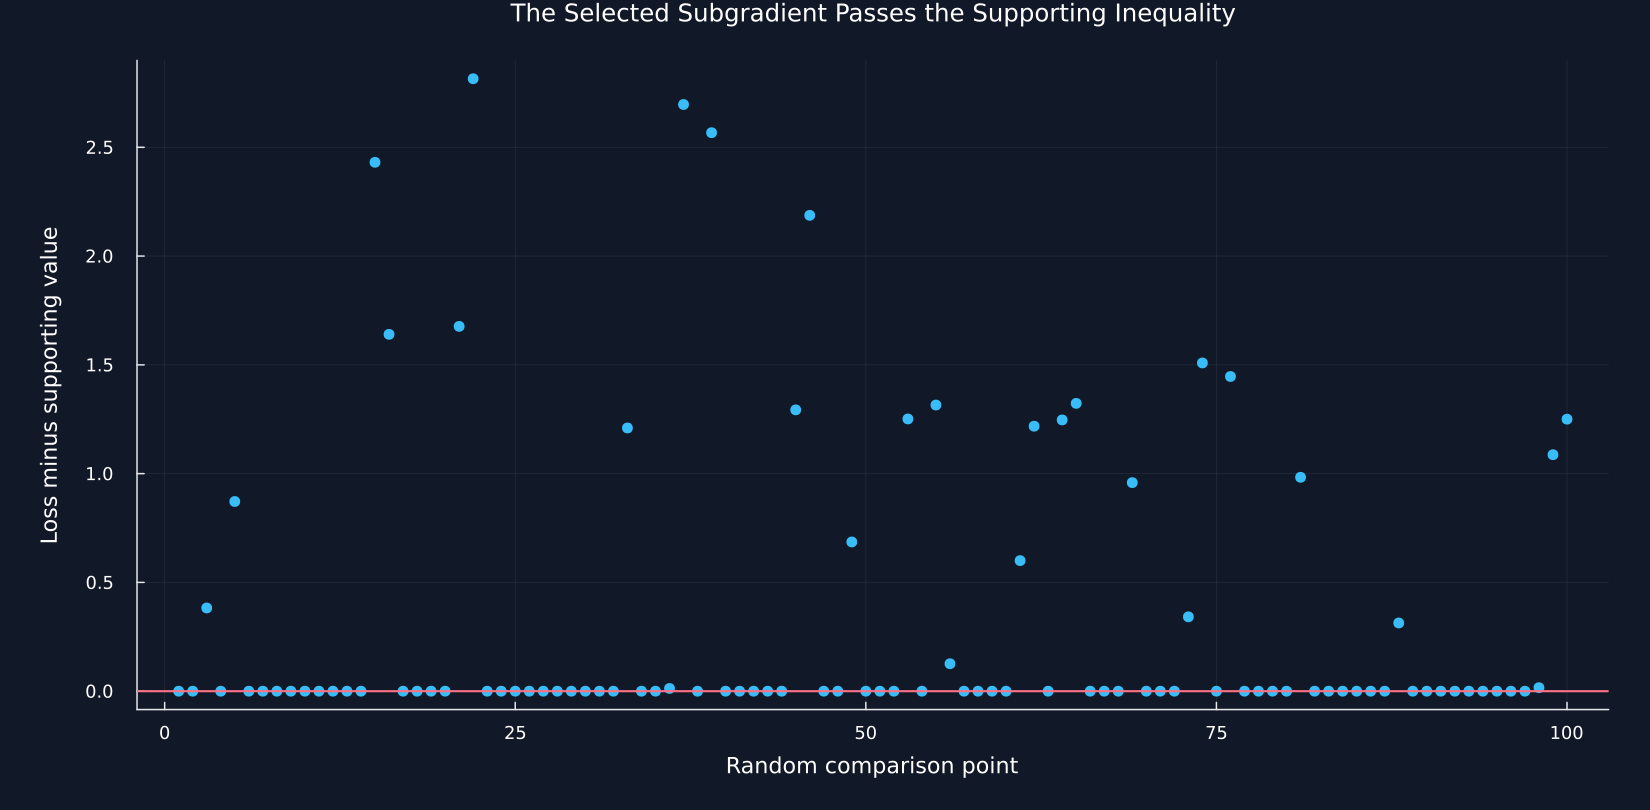

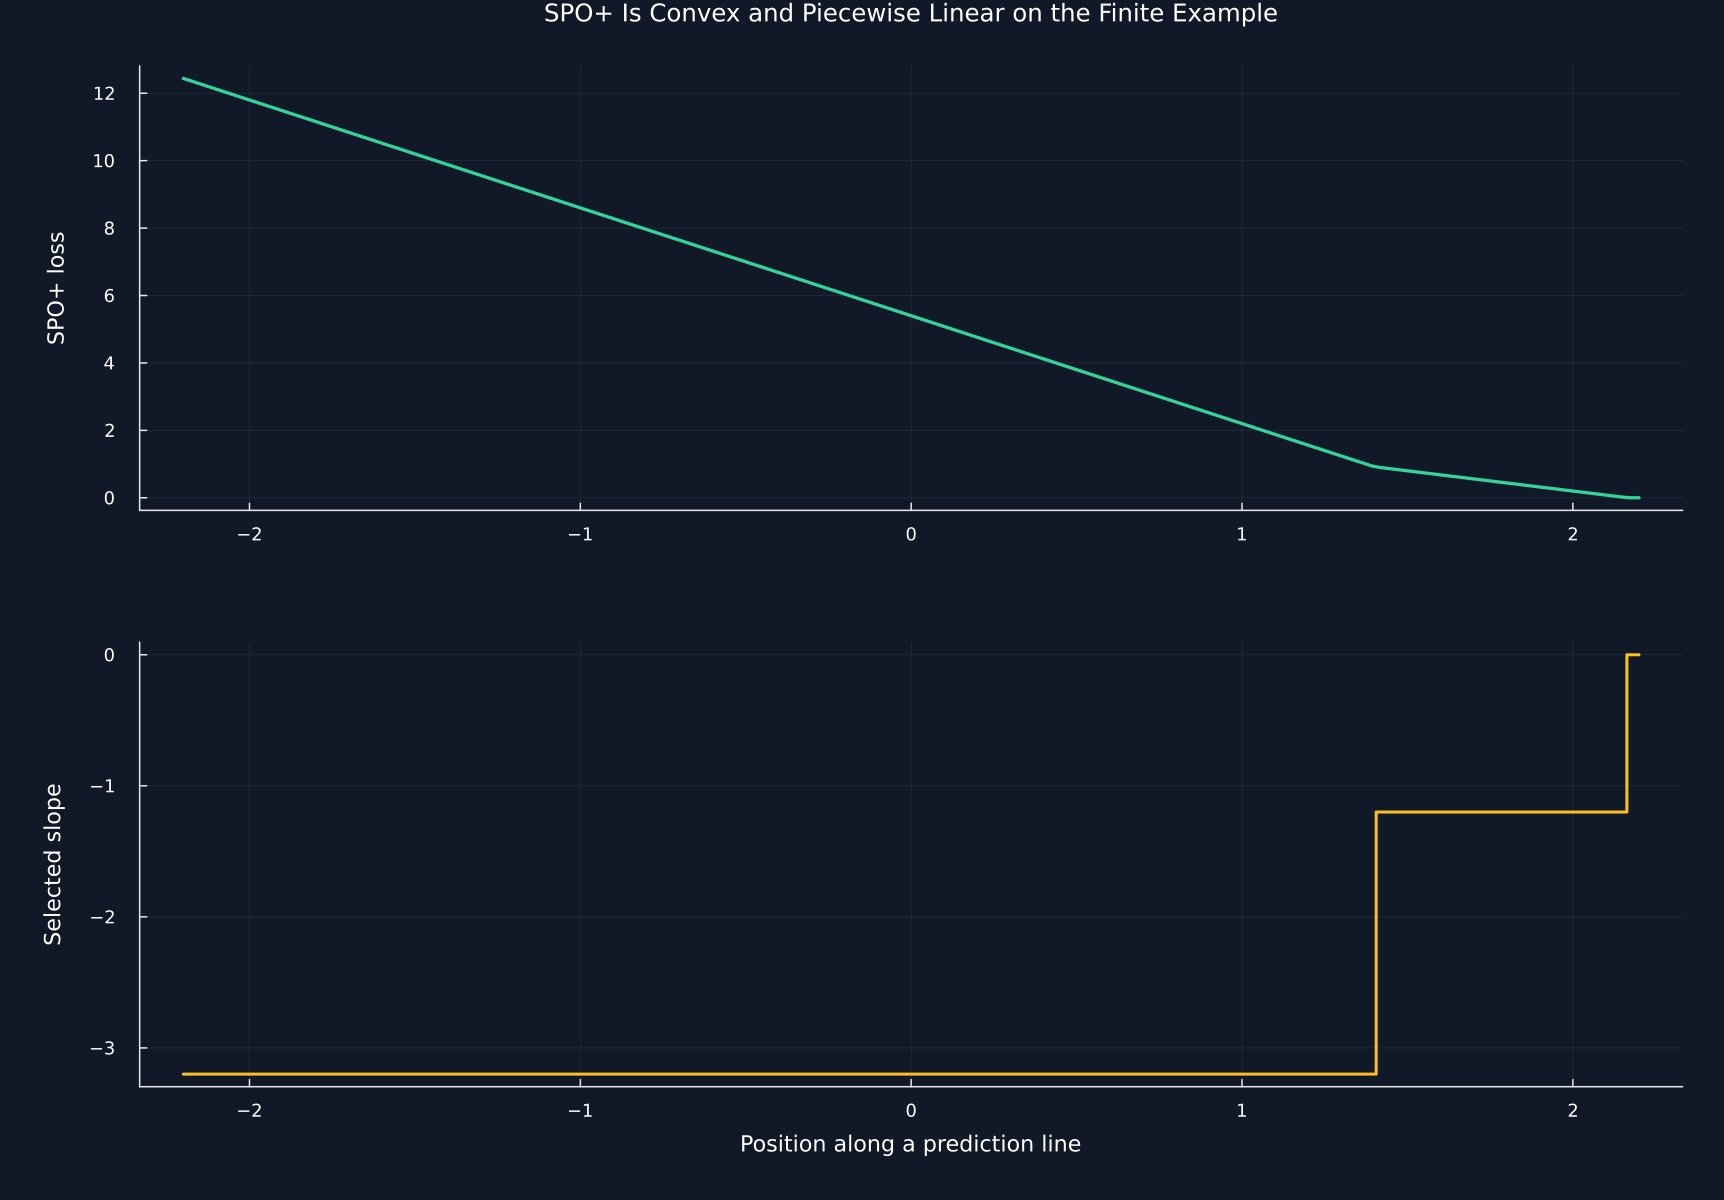

In [2]:
tensor_loss = spo_plus(predicted_cost,true_cost,vertices)
tensor_gradient = only(Zygote.gradient(prediction->spo_plus(prediction,true_cost,vertices),predicted_cost))
gradient_table = DataFrame("Component"=>[1,2],"RiskLabAI subgradient"=>result.subgradient,"Zygote gradient"=>tensor_gradient,"Absolute difference"=>abs.(result.subgradient-tensor_gradient))
@assert result.subgradient≈tensor_gradient
@assert tensor_loss≈result.loss
table(gradient_table,"spo_torch_gradient_checks","Selected SPO+ subgradient and native tensor gradient.")
shifted = primitive("comparison_points.csv")
margin_rows = NamedTuple[]
for (index,point) in enumerate(eachrow(shifted))
    shifted_loss = spo_plus_loss(point,true_cost,vertices).loss
    supporting_value = result.loss+dot(result.subgradient,point-predicted_cost)
    push!(margin_rows,(Draw=index,loss=shifted_loss,support=supporting_value,Margin=shifted_loss-supporting_value))
end
margin_table = DataFrame(margin_rows)
rename!(margin_table,["Draw","Shifted loss","Supporting value","Margin"])
@assert minimum(margin_table.Margin)>=-1e-12
inequality_checks = DataFrame("Check"=>["Random comparison points","Smallest convexity margin","Largest convexity margin"],"Value"=>[100,minimum(margin_table.Margin),maximum(margin_table.Margin)],"Pass"=>[nrow(margin_table)==100,minimum(margin_table.Margin)>=-1e-12,true])
table(inequality_checks,"spo_subgradient_inequality_checks","Finite supporting inequality checks for the selected subgradient.")
save_data(margin_table,paths,"subgradient_margins")
figure = scatter(margin_table.Draw,margin_table.Margin;color=palette.cyan,markersize=4,markerstrokewidth=0,legend=false,xlabel="Random comparison point",ylabel="Loss minus supporting value",title="The Selected Subgradient Passes the Supporting Inequality",size=(1100,540))
hline!(figure,[0];color=palette.rose,linewidth=1.4)
save_figure(figure,paths,"subgradient_margins")
direction = [1.0,-0.6]
grid = -2.2 .+ collect(0:180).*(4.4/180)
grid[end] = 2.2
slice_rows = NamedTuple[]
for value in grid
    item = spo_plus_loss(predicted_cost+value*direction,true_cost,vertices)
    push!(slice_rows,(Position=value,loss=item.loss,slope=dot(item.subgradient,direction),vertex=item.transformed_vertex-1))
end
slice_table = DataFrame(slice_rows)
rename!(slice_table,["Position","SPO+ loss","Directional subgradient","Transformed vertex"])
save_data(slice_table,paths,"spo_plus_slice")
p1 = plot(grid,slice_table[!,"SPO+ loss"];color=palette.green,linewidth=2.2,ylabel="SPO+ loss",title="SPO+ Is Convex and Piecewise Linear on the Finite Example",legend=false)
step_coordinates = vcat(first(grid),(grid[1:end-1]+grid[2:end])/2,last(grid))
step_values = vcat(slice_table[!,"Directional subgradient"],slice_table[end,"Directional subgradient"])
p2 = plot(step_coordinates,step_values;color=palette.amber,linewidth=2,seriestype=:steppost,ylabel="Selected slope",xlabel="Position along a prediction line",legend=false)
save_figure(plot(p1,p2;layout=(2,1),link=:x,size=(1150,800)),paths,"spo_plus_slice")


## Handling edge cases in decision loss

When $\widehat c=c$ and the observed best decision is unique, both the decision loss and SPO+ loss are zero. At a tie, the first supplied vertex is selected. These statements describe the declared finite oracle. They do not imply that the supplied vertices are a complete description of an unrelated optimization problem.

In [3]:
exact_result = spo_plus_loss(true_cost,true_cost,vertices)
tie_vertices = [0.0 0.0;1.0 0.0;0.0 1.0]
tie_result = spo_plus_loss(zeros(2),zeros(2),tie_vertices)
tie_checks = DataFrame("Case"=>["Exact costs away from ties","All costs tied"],"True vertex"=>[exact_result.true_vertex-1,tie_result.true_vertex-1],"Transformed vertex"=>[exact_result.transformed_vertex-1,tie_result.transformed_vertex-1],"Loss"=>[exact_result.loss,tie_result.loss],"Pass"=>[abs(exact_result.loss)<1e-12,tie_result.true_vertex==tie_result.transformed_vertex==1])
table(tie_checks,"spo_tie_and_exact_cost_checks","Exact-cost and first-index tie checks.")
invalid_calls = ["Cost dimensions differ"=>(() -> spo_plus_loss([1],[1,2],[1 2])),"Vertex list is empty"=>(() -> spo_plus_loss([1],[2],zeros(0,1))),"Nonfinite cost"=>(() -> spo_plus_loss([NaN,0],[1,2],[1 0;0 1]))]
invalid_rows = NamedTuple[]
for (name,call) in invalid_calls
    rejected,error_type = false,""
    try
        call()
    catch error
        error isa ArgumentError || rethrow()
        rejected,error_type = true,string(nameof(typeof(error)))
    end
    push!(invalid_rows,(Case=name,Rejected=rejected,Error=error_type))
end
invalid_table = DataFrame(invalid_rows)
@assert all(invalid_table.Rejected)
@assert all(tie_checks.Pass)
table(invalid_table,"spo_invalid_input_checks","Explicit rejection checks for invalid oracle inputs.")


Row,Case,True vertex,Transformed vertex,Loss,Pass
,String,Int64,Int64,Float64,String
1,Exact costs away from ties,2,2,0.0,Pass
2,All costs tied,0,0,0.0,Pass


Row,Case,Rejected,Error
,String,String,String
1,Cost dimensions differ,Pass,ArgumentError
2,Vertex list is empty,Pass,ArgumentError
3,Nonfinite cost,Pass,ArgumentError
